In [1]:
import os
import sys
from pathlib import Path

# Find project root
current_dir = Path.cwd()

possible_roots = [
    current_dir,
    current_dir.parent,
]

PROJECT_ROOT = None

for path in possible_roots:
    if (path / "src" / "data" / "dataset.py").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find project root containing src/data/dataset.py"
    )

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("Python path updated successfully.")

Project root: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
Python path updated successfully.


In [2]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd

from pathlib import Path
from src.data.dataset import get_dataset_splits

DATASET_PATH = "data/NEU-DET"

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

train, val, test = get_dataset_splits(DATASET_PATH)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Train: 1151
Validation: 288
Test: 360


Create bounding-box visualization function

In [3]:
def visualize_sample(sample, ax):

    image_path = sample["image"]

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    ax.imshow(image)

    for box, label in zip(
        sample["boxes"],
        sample["labels"]
    ):

        xmin, ymin, xmax, ymax = box

        # Convert normalized coordinates to pixels
        xmin = int(xmin * width)
        ymin = int(ymin * height)
        xmax = int(xmax * width)
        ymax = int(ymax * height)

        rectangle = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        class_name = CLASS_NAMES[int(label)]

        ax.text(
            xmin,
            max(ymin - 5, 0),
            class_name,
            color="yellow",
            backgroundcolor="black",
            fontsize=8
        )

    ax.set_title(Path(image_path).parent.name)
    ax.axis("off")

Visualize six training samples

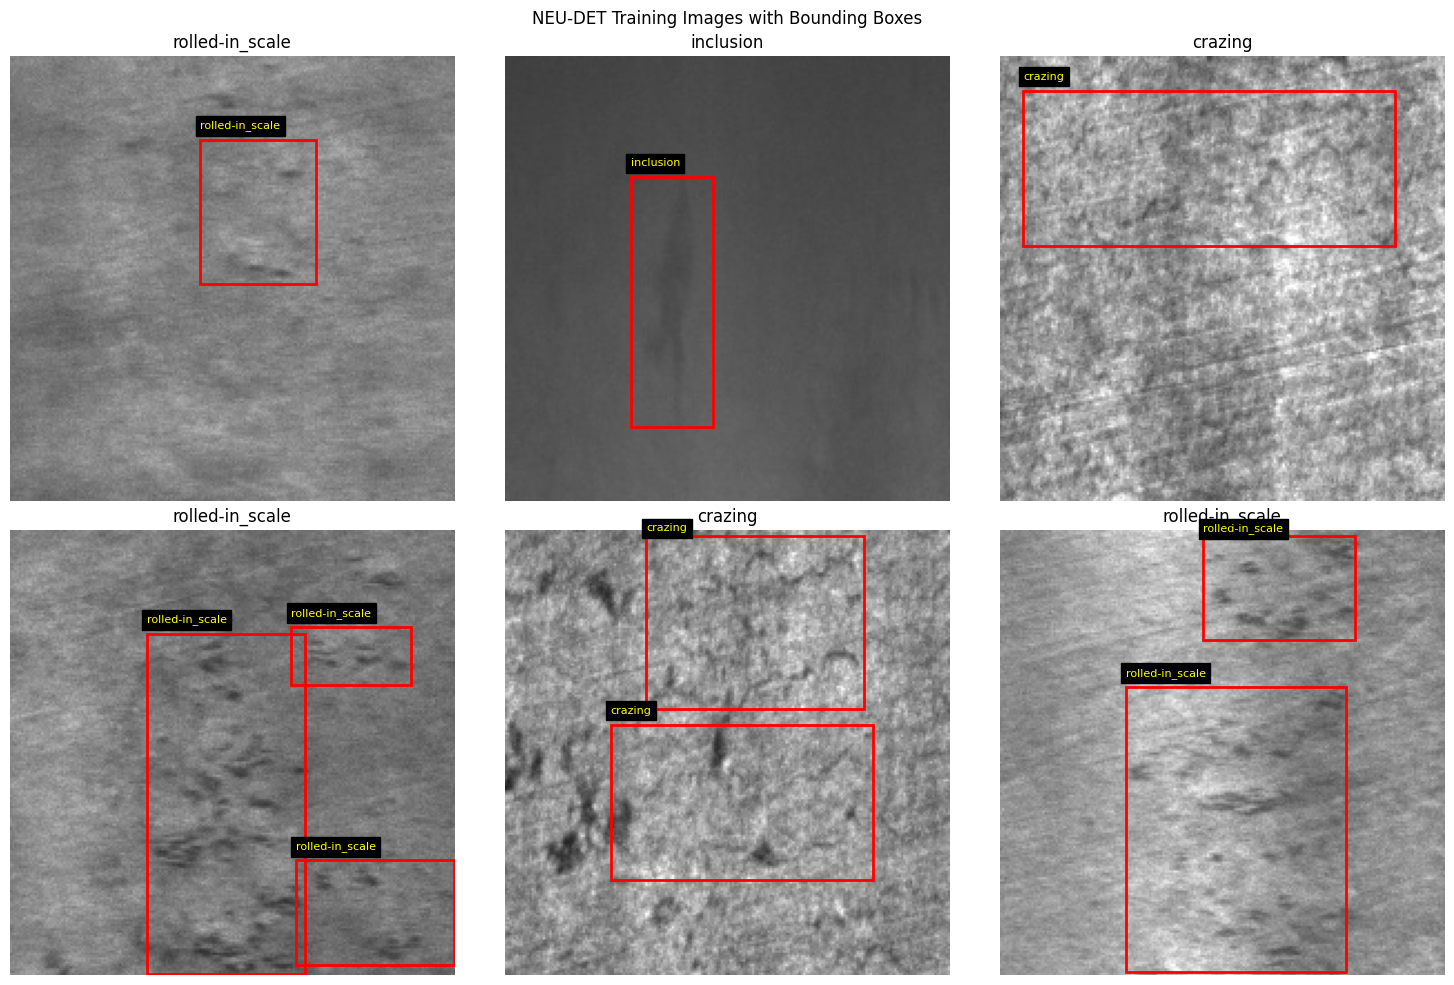

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flat):

    visualize_sample(train[i], ax)

plt.suptitle("NEU-DET Training Images with Bounding Boxes")
plt.tight_layout()
plt.show()

Visualize one example from each defect class

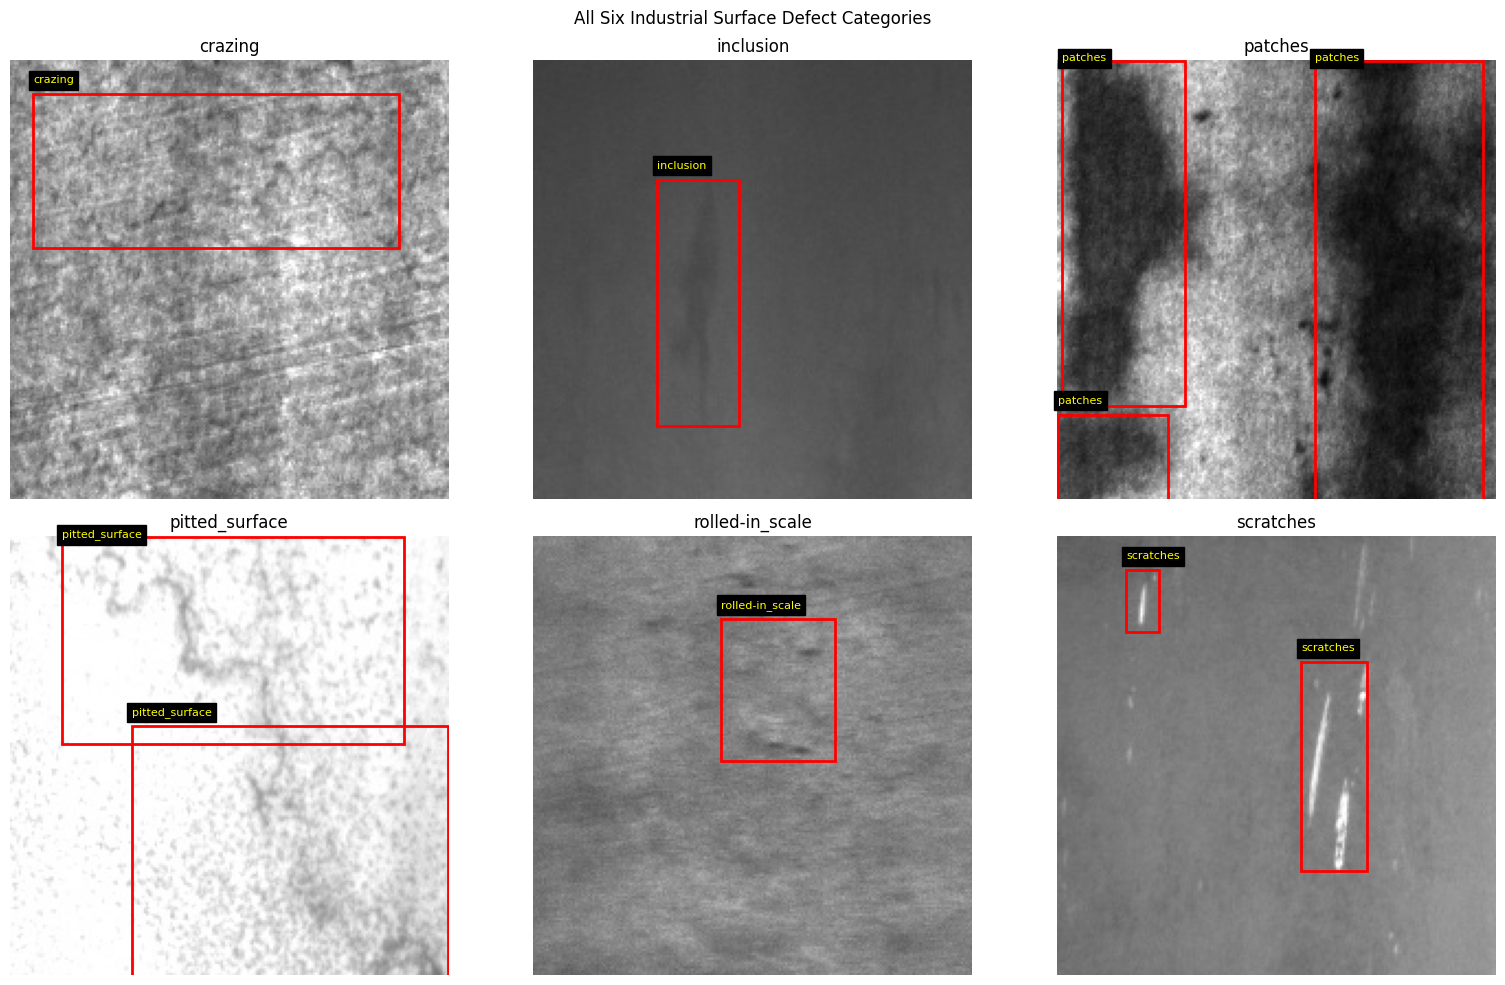

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for class_id, class_name in enumerate(CLASS_NAMES):

    sample = next(
        (
            item for item in train
            if class_id in item["labels"]
        ),
        None
    )

    ax = axes.flat[class_id]

    if sample is not None:
        visualize_sample(sample, ax)
    else:
        ax.set_title(f"No sample found: {class_name}")
        ax.axis("off")

plt.suptitle("All Six Industrial Surface Defect Categories")
plt.tight_layout()
plt.show()

Check bounding-box statistics

In [6]:
box_records = []

for sample in train:

    for box, label in zip(
        sample["boxes"],
        sample["labels"]
    ):

        xmin, ymin, xmax, ymax = box

        box_records.append({
            "class": CLASS_NAMES[int(label)],
            "width": xmax - xmin,
            "height": ymax - ymin,
            "area": (xmax - xmin) * (ymax - ymin)
        })

box_df = pd.DataFrame(box_records)

display(box_df.groupby("class").describe())

width                                                   \
                 count      mean       std    min     25%    50%    75%   
class                                                                     
crazing          419.0  0.606205  0.203894  0.190  0.4400  0.595  0.755   
inclusion        691.0  0.144899  0.076352  0.050  0.0950  0.125  0.175   
patches          557.0  0.284686  0.109354  0.090  0.2050  0.260  0.355   
pitted_surface   267.0  0.652828  0.269307  0.130  0.4125  0.640  0.950   
rolled-in_scale  399.0  0.355013  0.135482  0.105  0.2450  0.330  0.440   
scratches        343.0  0.185437  0.236245  0.040  0.0750  0.100  0.160   

                       height            ...                  area            \
                   max  count      mean  ...     75%    max  count      mean   
class                                    ...                                   
crazing          0.995  419.0  0.385835  ...  0.4525  0.985  419.0  0.228299   
inclusion        0.690  691.0  0.423177  ...  0.6000  0.995  691.0  0.071675   
patches          0.795  557.0  0.422415  ...  0.5600  0.995  557.0  0.131174   
pitted_surface   0.995  267.0  0.880000  ...  0.9900  0.995  267.0  0.587165   
rolled-in_scale  0.835  399.0  0.369060  ...  0.4650  0.980  399.0  0.134662   
scratches        0.995  343.0  0.700277  ...  0.9850  0.995  343.0  0.092348   

                                                                            
                      std      min       25%       50%       75%       max  
class                                                                       
crazing          0.106778  0.05600  0.151125  0.204350  0.290313  0.916800  
inclusion        0.072904  0.00605  0.020900  0.039650  0.102025  0.497250  
patches          0.104025  0.00975  0.054450  0.094050  0.178750  0.660250  
pitted_surface   0.283190  0.02080  0.352900  0.562600  0.885200  0.990025  
rolled-in_scale  0.087071  0.01360  0.065200  0.113100  0.182550  0.589000  
scratches        0.064311  0.00990  0.047075  0.073875  0.133650  0.455900  

[6 rows x 24 columns]